In [58]:
%pip install opencv-python numpy matplotlib scipy
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached scikit_image-0.26.0-cp314-cp314-win_amd64.whl.metadata (15 kB)
Using cached scikit_image-0.26.0-cp314-cp314-win_amd64.whl (12.0 MB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 66.9 MB/s  0:00:00

   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
 


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Dimensões: (1600, 1200, 3)


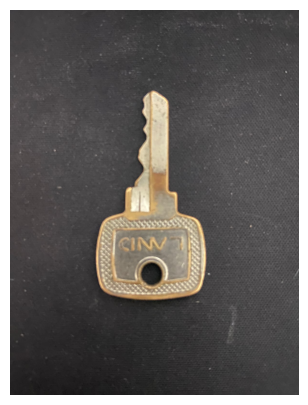

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import clear_border

imagem = cv2.imread("../imagens/PD 442.jpeg")

if imagem is None:
    raise FileNotFoundError("Imagem não encontrada")

imagem_rgb = cv2.cvtColor(
    imagem,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 5))
plt.imshow(imagem_rgb)
plt.axis("off")

print("Dimensões:", imagem.shape)

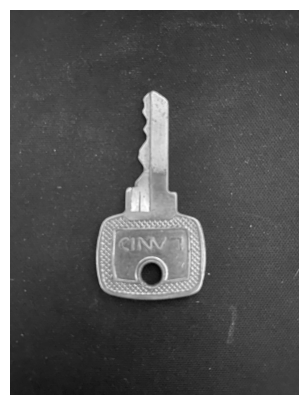

In [2]:
gray = cv2.cvtColor(
    imagem,
    cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(10, 5))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

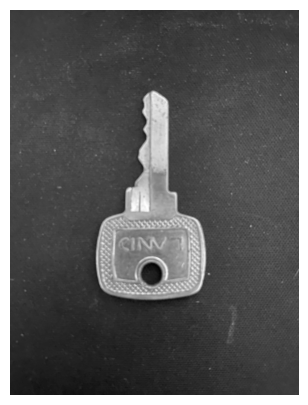

In [3]:
blur = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

plt.figure(figsize=(10, 5))
plt.imshow(blur, cmap="gray")
plt.axis("off")
plt.show()

Limiar escolhido: 118.0


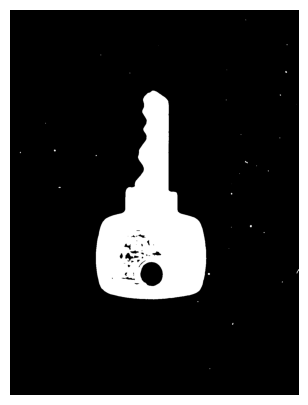

In [4]:
limiar, binary = cv2.threshold(
    blur,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

binary_inverted = cv2.bitwise_not(binary)

print("Limiar escolhido:", limiar)

plt.figure(figsize=(10, 5))
plt.imshow(binary_inverted, cmap="gray")
plt.axis("off")
plt.show()

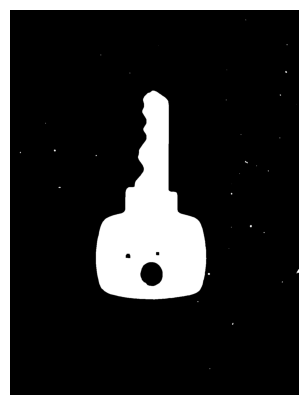

In [5]:
kernel = np.ones((11, 11), dtype=np.uint8)

closed = cv2.morphologyEx(
    binary_inverted,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(10, 5))
plt.imshow(closed, cmap="gray")
plt.axis("off")
plt.show()

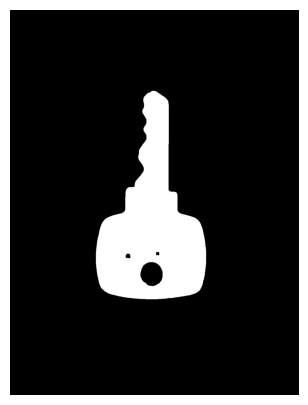

In [6]:
kernel = np.ones((11, 11), dtype=np.uint8)

opened = cv2.morphologyEx(
    closed,
    cv2.MORPH_OPEN,
    kernel
)

plt.figure(figsize=(10, 5))
plt.imshow(opened, cmap="gray")
plt.axis("off")
plt.show()

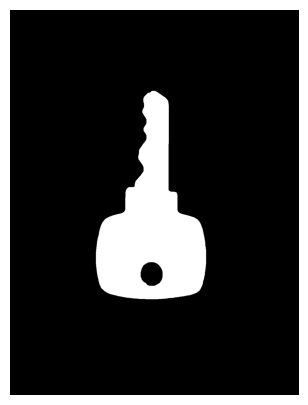

In [7]:
kernel = np.ones((15, 15), dtype=np.uint8)

clear = cv2.morphologyEx(
    opened,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(10, 5))
plt.imshow(clear, cmap="gray")
plt.axis("off")
plt.show()

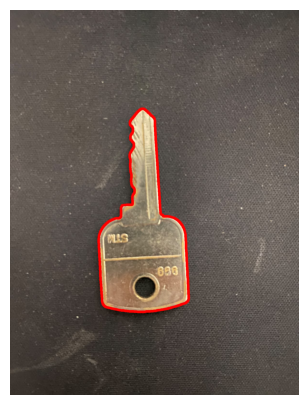

In [81]:
clear_b = clear_border(clear)

contours, hierarchy = cv2.findContours(
    clear_b,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE
)

if not contours:
    raise ValueError("Nenhum contorno encontrado")

contorno_chave = max(
    contours,
    key=cv2.contourArea
)

resultado = imagem.copy()

cv2.drawContours(
    resultado,
    [contorno_chave],
    -1,
    (0, 0, 255),
    10
)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [67]:
area = cv2.contourArea(contorno_chave)

perimetro = cv2.arcLength(
    contorno_chave,
    True
)

x, y, w, h = cv2.boundingRect(contorno_chave)

momentos = cv2.moments(contorno_chave)

if momentos["m00"] != 0:
    cx = int(momentos["m10"] / momentos["m00"])
    cy = int(momentos["m01"] / momentos["m00"])
else:
    cx, cy = x + w // 2, y + h // 2

print("Área:", area, "pixels²")
print("Perímetro:", perimetro, "pixels")
print("Largura da bounding box:", w)
print("Altura da bounding box:", h)
print("Centroide:", (cx, cy))

Área: 147514.0 pixels²
Perímetro: 2060.670258283615 pixels
Largura da bounding box: 388
Altura da bounding box: 754
Centroide: (694, 777)
